We would like to extend similarity-based Lesk algorithm to include phonetic matching, which evaluates phonetically similar wording. For this purpose, use the “Fuzzy” library in python to generate the character string that identifies phonetically similar words, and then use edit distance to compute the phonetic similarity between two words. See an example of implementation at https://www.analyticsvidhya.com/blog/2017/01/ultimate-guide-to-understand-implement-natural-language-processing-codes-in-python/. Demonstrate this reasoning on the example sentence pointed out in 1) and generate a matrix that indicates the phonetic distance between each pair of words of the sentence.

In [1]:
import utils as u
import numpy as np
import matplotlib.pyplot as plt

SENTENCE = "I have been prescribed two important drugs today during my visit to clinic"

# The following languages are: English, Italian, Finnish, French, German, Spanish, Russian
VARIANTS = {
    "English": SENTENCE,
    "Italian": "Oggi mi sono state prescritte due importanti medicine durante la mia visita alla clinica",
    "Finnish": "Minulle määrättiin tänään kaksi tärkeää lääkettä klinikkakäynnilläni",
    "French": "On m'a prescrit deux médicaments importants aujourd'hui, lors de ma visite à la clinique",
    "German": "Mir wurden heute bei meinem Klinikbesuch zwei wichtige Medikamente verschrieben",
    "Spanish": "Hoy me han recetado dos medicamenti importantes durante mi visita a la clínica",
    "Russian": "Segodnya vo vremya vizita v kliniku mne naznachili dva vazhnykh preparata",
}

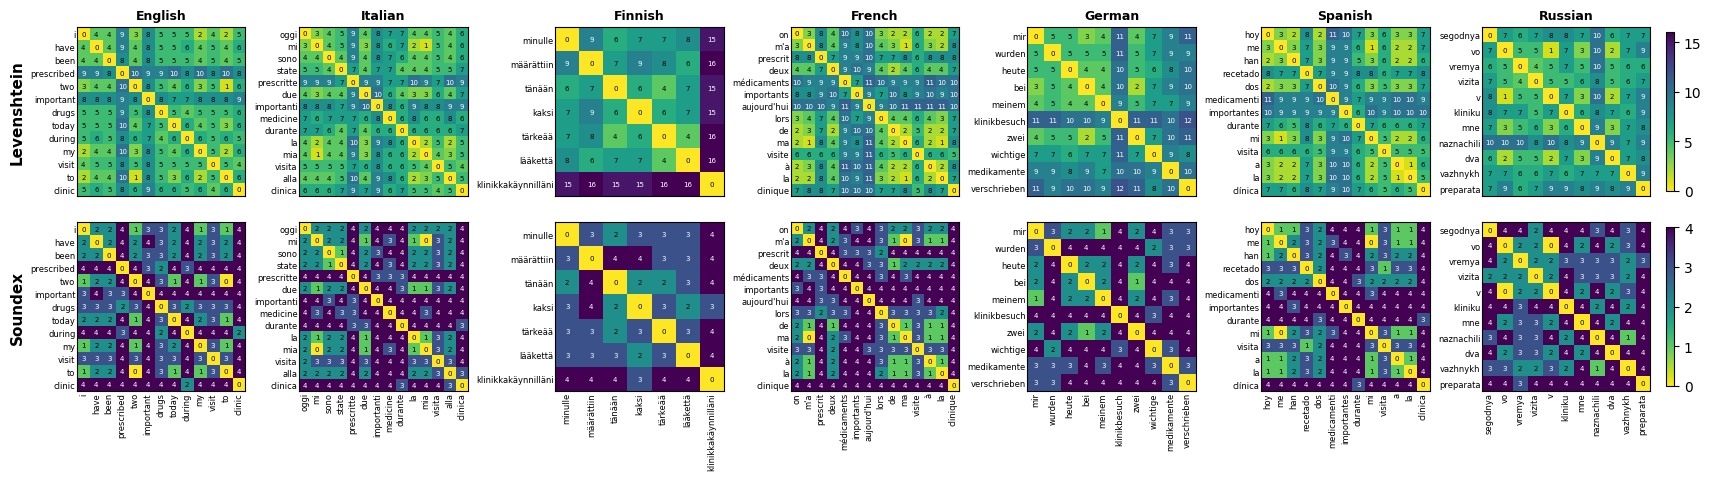

In [2]:
tokens = [w.lower() for w in SENTENCE.split()]

def levenshtein_matrix(words):
    """ Returns the matrix representation of all the permutations of levenshtein dinstances of the words in the given vector """
    n = len(words)
    matrix = np.zeros((n, n), dtype=int)
    for i in range(n):
        for j in range(i + 1, n):
            matrix[i, j] = matrix[j, i] = u.levenshtein(words[i], words[j])

    return matrix

def levenshtein_soundex_matrix(words):
    """ Returns the matrix representation of all the permutations of levenshtein dinstances of the soundex output of words in the given vector """
    n = len(words)
    matrix = np.zeros((n, n), dtype=int)
    for i in range(n):
        for j in range(i + 1, n):
            matrix[i, j] = matrix[j, i] = u.levenshtein(u.soundex(words[i]), u.soundex(words[j]))

    return matrix

def plot_matrix(ax, matrix, words, title, vmax, show_xticks=True):
    """Draw a distance matrix as a heatmap on the given axes and return the image (for the colorbar)."""
    image = ax.imshow(matrix, cmap="viridis_r", vmin=0, vmax=vmax)

    ax.set_xticks(range(len(words)), words if show_xticks else [], rotation=90, fontsize=6)
    ax.set_yticks(range(len(words)), words, fontsize=6)
    ax.tick_params(length=0, pad=1)

    for i in range(len(words)):
        for j in range(len(words)):
            color = "white" if matrix[i, j] > vmax / 2 else "black"
            ax.text(j, i, matrix[i, j], ha="center", va="center", fontsize=5, color=color)

    ax.set_title(title, fontsize=9, fontweight="bold")
    return image

# Analysis: one column per language, Levenshtein on top and Soundex below (shared color scale per row)
sentences = {lang: [w.strip(".,;:!?").lower() for w in s.split()] for lang, s in VARIANTS.items()}
lev = {lang: levenshtein_matrix(words) for lang, words in sentences.items()}
sdx = {lang: levenshtein_soundex_matrix(words) for lang, words in sentences.items()}
lev_max = max(m.max() for m in lev.values())
sdx_max = max(m.max() for m in sdx.values())

fig, axes = plt.subplots(2, len(VARIANTS), figsize=(17, 4.7), layout="constrained")

for (lang, words), col in zip(sentences.items(), axes.T):
    lev_image = plot_matrix(col[0], lev[lang], words, lang, lev_max, show_xticks=False)
    sdx_image = plot_matrix(col[1], sdx[lang], words, "", sdx_max)

axes[0, 0].set_ylabel("Levenshtein", fontsize=11, fontweight="bold")
axes[1, 0].set_ylabel("Soundex", fontsize=11, fontweight="bold")
fig.colorbar(lev_image, ax=axes[0], shrink=0.85, pad=0.01)
fig.colorbar(sdx_image, ax=axes[1], shrink=0.85, pad=0.01)

fig.savefig("distance_matrices.png", dpi=200)
plt.show()
